In [ ]:
!pip install pymoo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 2.9 MB/s eta 0:00:00


In [ ]:
!pip install lifelines matplotlib

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 6.4 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4120 sha256=7febcb745ce7e51c8e72ef8bab6b1c6c5018646fc1dda41f7ce8cdca991cbd6d
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma


In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.ensemble import AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
import matplotlib.pyplot as plt
from sklearn.base import clone
from collections import Counter
import shap
import math
from matplotlib import gridspec
from lifelines import CoxPHFitter
from matplotlib.patches import Rectangle
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import inspect
import warnings

In [ ]:
df = pd.read_csv('sample_dataset.csv')
df

,ARHGEF10L,HIF3A,RNF17,RNF10,RNF11,RNF13,GTF2IP1,REM1,MTVR2,RTN4RL2,...,NPY5R,GNGT2,GNGT1,TULP3,PTRF,BCL6B,GSTK1,SELP,SELS,TumorType
0,10.4567,7.2366,0.4503,12.2288,11.8107,9.9902,12.4704,5.2615,0.0000,5.2337,...,0.4503,5.3288,0.0000,9.0782,11.2214,6.7833,11.6090,2.4317,11.0901,Metastatic
1,8.3968,3.3893,0.0000,10.7424,10.4744,10.0415,12.4793,6.0612,0.3642,4.1423,...,3.6753,5.8901,0.0000,8.2274,11.9460,7.9559,10.9525,8.3120,9.4945,Metastatic
2,9.2700,1.4948,0.0000,12.1100,9.9002,10.2235,12.3415,2.8804,0.3818,5.3576,...,0.0000,3.1003,0.0000,10.4935,12.9077,6.7464,10.9070,3.9011,9.9979,Metastatic
3,9.3631,1.0980,0.3619,11.3904,9.8809,10.4280,12.3516,3.4938,0.0000,3.7291,...,0.0000,2.1446,0.0000,9.7932,12.4875,6.3319,11.0666,5.5778,10.3930,Primary
4,10.3084,4.3705,0.0000,11.6203,11.0004,11.4038,11.4320,5.6460,0.8733,6.2766,...,0.0000,6.1639,0.0000,9.1866,13.4410,9.6435,11.3559,9.0879,10.3138,Metastatic
5,9.1462,2.5251,1.5762,11.3769,10.7846,10.7288,12.7243,7.3912,0.0000,4.5358,...,3.0240,5.2121,2.7113,9.3838,13.2109,7.5912,11.5564,4.4337,10.1872,Metastatic
6,10.4445,0.4985,0.0000,11.9165,10.5825,10.2866,12.3080,4.6872,0.0000,5.4970,...,0.0000,5.3145,2.8461,9.5525,13.1218,5.9270,12.6922,6.2501,10.0843,Primary
7,9.4095,0.7433,0.0000,11.7101,9.8685,10.3824,11.5194,2.4278,0.0000,5.7066,...,0.0000,5.4638,0.0000,10.6387,13.9959,6.4913,12.0457,6.4136,10.0624,Metastatic
8,10.3927,1.2454,0.0000,11.5568,10.6654,10.3338,12.5589,2.0301,0.0000,3.5390,...,0.0000,3.1509,0.4251,10.1397,9.7507,5.6241,11.7218,3.2581,10.0921,Metastatic
9,10.3279,0.6003,0.0000,12.3950,9.9119,8.3829,11.7669,3.7424,0.6003,7.1112,...,0.0000,4.2525,0.0000,10.1480,12.8231,6.9216,11.7469,4.4008,9.7371,Primary


**Step-1: Preliminary Gene Screening**

In [ ]:
X = df.drop(columns=['TumorType'], errors='ignore')
y = (df['TumorType'] == 'Metastatic').astype(int)   # 1 = metastatic (positive class), 0 = primary

# ============================================================
# Feature selection settings
# ============================================================

feature_numbers = [300, 400, 500, 600, 700, 800, 900, 1000]

MI_RANDOM_STATE = 42

mi_kwargs = {"random_state": MI_RANDOM_STATE}
if "n_jobs" in inspect.signature(mutual_info_classif).parameters:
    mi_kwargs["n_jobs"] = -1          # parallel MI, available in scikit-learn >= 1.5


def anova_scores(X_fit, y_fit):
    """ANOVA F-statistic of every gene (larger = stronger group difference)."""
    with warnings.catch_warnings(), np.errstate(divide="ignore", invalid="ignore"):
        warnings.simplefilter("ignore")   # constant genes give an undefined F; they are ranked last
        f_values, _ = f_classif(X_fit, y_fit)
    return f_values


def mi_scores(X_fit, y_fit):
    """Mutual information between every gene and the class label."""
    return mutual_info_classif(X_fit, y_fit, **mi_kwargs)


selection_methods = {
    "ANOVA": anova_scores,
    "Mutual_Information": mi_scores
}


def top_k_columns(scores, k):
    """Column positions of the k highest-scoring genes.

    Same rule as scikit-learn's SelectKBest: genes with an undefined score
    are ranked last, ties are broken by a stable sort, and the selected
    columns are returned in their original order.
    """
    s = np.asarray(scores, dtype=float).copy()
    s[np.isnan(s)] = np.finfo(s.dtype).min
    return np.sort(np.argsort(s, kind="mergesort")[-k:])


# ============================================================
# Classifiers
# ============================================================

classifiers = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.1,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_split=2,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boost": GradientBoostingClassifier(
        learning_rate=0.1,
        max_depth=5,
        n_estimators=200,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Logistic Regression": LogisticRegression(
        C=1,
        penalty="l1",
        random_state=42,
        solver="liblinear",
        max_iter=500
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        min_samples_split=5,
        max_depth=None,
        random_state=42
    ),

    "SVC": SVC(
        C=0.1,
        class_weight=None,
        gamma="scale",
        kernel="linear",
        probability=True
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=300,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=11,
        eval_metric="logloss"
    )
}


# ============================================================
# Cross-validation setup
# ============================================================

n_splits = 5
skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

usable_feature_numbers = []
for k in feature_numbers:
    if k > X.shape[1]:
        print(f"Skipping k={k}, because X only has {X.shape[1]} features.")
    else:
        usable_feature_numbers.append(k)


# ============================================================
# Run feature selection + classifier evaluation
# Gene ranking happens inside each fold, on the training samples only
# ============================================================

fold_metrics = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):

    print(f"\n==============================")
    print(f"Fold {fold}/{n_splits}: {len(train_idx)} training samples, {len(test_idx)} test samples")
    print(f"==============================")

    X_train_all = X.iloc[train_idx]
    X_test_all = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    for selection_name, score_function in selection_methods.items():

        # Rank all genes using the TRAINING samples of this fold only
        fold_scores = score_function(X_train_all, y_train)

        for k in usable_feature_numbers:

            # Keep the top k genes of this fold's ranking
            selected_cols = top_k_columns(fold_scores, k)

            X_train = X_train_all.iloc[:, selected_cols]
            X_test = X_test_all.iloc[:, selected_cols]

            # Evaluate each classifier
            for clf_name, clf in classifiers.items():

                model = clone(clf)
                model.fit(X_train, y_train)     # whole training fold

                y_pred = model.predict(X_test)

                acc = accuracy_score(y_test, y_pred)
                prec = precision_score(y_test, y_pred, average="binary", zero_division=0)
                rec = recall_score(y_test, y_pred, average="binary", zero_division=0)
                f1 = f1_score(y_test, y_pred, average="binary", zero_division=0)

                fold_metrics.append({
                    "Selection_Method": selection_name,
                    "Number_of_Features": k,
                    "Classifier": clf_name,
                    "Fold": fold,
                    "Accuracy": acc,
                    "Precision": prec,
                    "Recall": rec,
                    "F1-score": f1
                })

            print(f"Fold {fold} | {selection_name} | Top {k}: done")


# ============================================================
# Average the five folds for every (selection method, k, classifier)
# ============================================================

fold_results_df = pd.DataFrame(fold_metrics)

fold_results_df.to_csv(
    "all_feature_selection_classifier_results_per_fold.csv",
    index=False
)

print("\nSaved: all_feature_selection_classifier_results_per_fold.csv")

all_results = []

for selection_name in selection_methods:

    print(f"\n==============================")
    print(f"Feature Selection: {selection_name}")
    print(f"==============================")

    for k in usable_feature_numbers:

        for clf_name in classifiers:

            rows = fold_results_df[
                (fold_results_df["Selection_Method"] == selection_name) &
                (fold_results_df["Number_of_Features"] == k) &
                (fold_results_df["Classifier"] == clf_name)
            ]

            accs = rows["Accuracy"].to_numpy()
            precs = rows["Precision"].to_numpy()
            recs = rows["Recall"].to_numpy()
            f1s = rows["F1-score"].to_numpy()

            avg_result = {
                "Selection_Method": selection_name,
                "Number_of_Features": k,
                "Classifier": clf_name,
                "Accuracy": np.mean(accs),
                "Accuracy_std": np.std(accs),
                "Precision": np.mean(precs),
                "Precision_std": np.std(precs),
                "Recall": np.mean(recs),
                "Recall_std": np.std(recs),
                "F1-score": np.mean(f1s),
                "F1-score_std": np.std(f1s)
            }

            all_results.append(avg_result)

            print(
                f"{selection_name} | Top {k} | {clf_name}: "
                f"Accuracy = {avg_result['Accuracy']:.3f} ± {avg_result['Accuracy_std']:.3f}, "
                f"Precision = {avg_result['Precision']:.3f} ± {avg_result['Precision_std']:.3f}, "
                f"Recall = {avg_result['Recall']:.3f} ± {avg_result['Recall_std']:.3f}, "
                f"F1 = {avg_result['F1-score']:.3f} ± {avg_result['F1-score_std']:.3f}"
            )


# ============================================================
# Save all classifier results
# ============================================================

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    "all_feature_selection_classifier_results.csv",
    index=False
)

print("\nSaved: all_feature_selection_classifier_results.csv")


# ============================================================
# Compare feature sets based on accuracy
# Average over all classifiers for each feature-selection setting
# ============================================================

feature_set_comparison = (
    results_df
    .groupby(["Selection_Method", "Number_of_Features"])
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_F1=("F1-score", "mean")
    )
    .reset_index()
    .sort_values(by="Mean_Accuracy", ascending=False)
)

feature_set_comparison.to_csv(
    "feature_set_accuracy_comparison.csv",
    index=False
)

print("\nSaved: feature_set_accuracy_comparison.csv")

print(f"\nAccuracy comparison between all {len(feature_set_comparison)} feature sets:")
print(feature_set_comparison)


# ============================================================
# Best classifier-level result
# (highest mean accuracy; the first one wins if there is a tie, as before)
# ============================================================

best_row = results_df.loc[results_df["Accuracy"].idxmax()]

best_accuracy = float(best_row["Accuracy"])
best_selection_method = best_row["Selection_Method"]
best_k = int(best_row["Number_of_Features"])
best_classifier = best_row["Classifier"]

print("\n======================================")
print("Most optimal feature set based on accuracy")
print("======================================")
print(f"Selection method: {best_selection_method}")
print(f"Number of features: {best_k}")
print(f"Best classifier: {best_classifier}")
print(f"Best accuracy: {best_accuracy:.4f} ± {float(best_row['Accuracy_std']):.4f}")


# ============================================================
# Final gene set for Step 2
# The accuracy above was estimated without the test folds.
# The gene list itself is now selected from ALL samples, as before.
# ============================================================

final_scores = selection_methods[best_selection_method](X, y)
best_selected_features = X.columns[top_k_columns(final_scores, best_k)]


# ============================================================
# Save dataframe with the most optimal feature set
# ============================================================

optimal_feature_df = pd.concat(
    [
        df[["index"]].reset_index(drop=True) if "index" in df.columns else pd.DataFrame(),
        X[best_selected_features].reset_index(drop=True),
        y.reset_index(drop=True).rename("TumorType")
    ],
    axis=1
)

optimal_filename = (
    f"SKCM_best_{best_selection_method}_top{best_k}_features.csv"
)

optimal_feature_df.to_csv(optimal_filename, index=False)

print(f"\nSaved optimal feature dataset: {optimal_filename}")


Fold 1/5: 32 training samples, 8 test samples
Fold 1 | ANOVA | Top 300: done
Fold 1 | ANOVA | Top 400: done
Fold 1 | ANOVA | Top 500: done
Fold 1 | ANOVA | Top 600: done
Fold 1 | ANOVA | Top 700: done
Fold 1 | ANOVA | Top 800: done
Fold 1 | ANOVA | Top 900: done
Fold 1 | ANOVA | Top 1000: done
Fold 1 | Mutual_Information | Top 300: done
Fold 1 | Mutual_Information | Top 400: done
Fold 1 | Mutual_Information | Top 500: done
Fold 1 | Mutual_Information | Top 600: done
Fold 1 | Mutual_Information | Top 700: done
Fold 1 | Mutual_Information | Top 800: done
Fold 1 | Mutual_Information | Top 900: done
Fold 1 | Mutual_Information | Top 1000: done

Fold 2/5: 32 training samples, 8 test samples
Fold 2 | ANOVA | Top 300: done
Fold 2 | ANOVA | Top 400: done
Fold 2 | ANOVA | Top 500: done
Fold 2 | ANOVA | Top 600: done
Fold 2 | ANOVA | Top 700: done
Fold 2 | ANOVA | Top 800: done
Fold 2 | ANOVA | Top 900: done
Fold 2 | ANOVA | Top 1000: done
Fold 2 | Mutual_Information | Top 300: done
Fold 2 | Mu

**Step-2: Pareto Optimal Gene Refinement**


==== Running NSGA-II feature selection with CV for Naive Bayes ====
Model: Naive Bayes, Fold 1/5
Model: Naive Bayes, Fold 2/5
Model: Naive Bayes, Fold 3/5
Model: Naive Bayes, Fold 4/5
Model: Naive Bayes, Fold 5/5

==== Running NSGA-II feature selection with CV for KNN ====
Model: KNN, Fold 1/5
Model: KNN, Fold 2/5
Model: KNN, Fold 3/5
Model: KNN, Fold 4/5
Model: KNN, Fold 5/5

==== Running NSGA-II feature selection with CV for Logistic Regression ====
Model: Logistic Regression, Fold 1/5
Model: Logistic Regression, Fold 2/5
Model: Logistic Regression, Fold 3/5
Model: Logistic Regression, Fold 4/5
Model: Logistic Regression, Fold 5/5

==== Running NSGA-II feature selection with CV for Random Forest ====
Model: Random Forest, Fold 1/5
Model: Random Forest, Fold 2/5
Model: Random Forest, Fold 3/5
Model: Random Forest, Fold 4/5
Model: Random Forest, Fold 5/5

Saved all Pareto front results to CV_ParetoFront_SelectedModels.csv


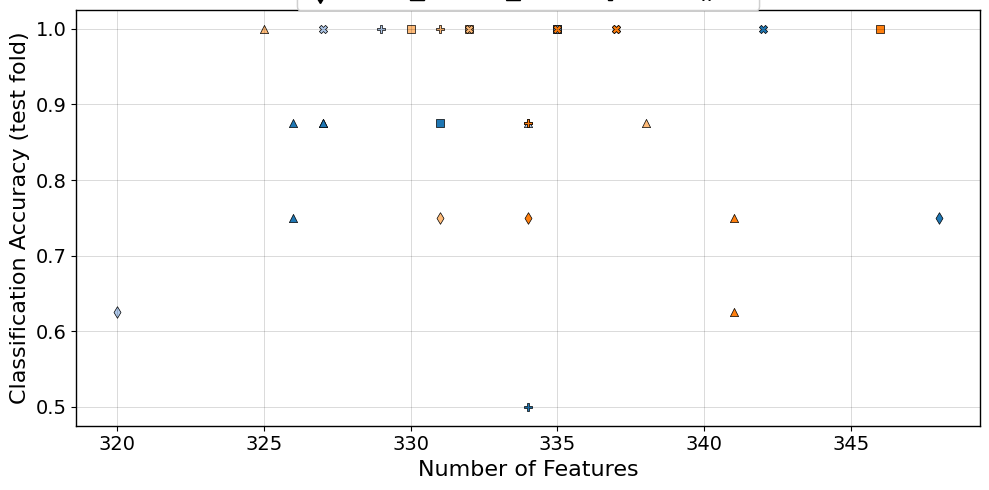


Pareto-optimal solutions per model (all folds pooled):
            Solutions  Mean_Features  Mean_Test_Accuracy  Std_Test_Accuracy
Classifier                                                                 
NB                  8       332.6250              0.8125             0.1494
KNN                 6       330.0000              0.9167             0.1514
LR                  9       337.6667              0.8750             0.1398
RF                  7       331.2857              0.9464             0.0983


In [ ]:

df1 = pd.read_csv('SKCM_best_Mutual_Information_top900_features.csv') #Update the filename
X = df1.drop(columns=['TumorType'], errors='ignore')
y = df1['TumorType']

feature_names = X.columns.tolist()

ALL_MODELS = {
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=None, min_samples_split=2, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "Gradient Boost": GradientBoostingClassifier(learning_rate=0.1, max_depth=5, n_estimators=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(C=1, penalty='l1', solver='liblinear', max_iter=500, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_split=5, max_depth=None, random_state=42),
    "SVC": SVC(C=0.1, class_weight=None, gamma='scale', kernel='linear', probability=True),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=11, eval_metric='logloss'),
    "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', alpha=1e-4, learning_rate_init=1e-3, max_iter=200, random_state=42),
}

ABBR = {
    "AdaBoost": "AB",
    "Decision Tree": "DT",
    "Extra Trees": "ET",
    "Gradient Boost": "GB",
    "KNN": "KNN",
    "Logistic Regression": "LR",
    "Naive Bayes": "NB",
    "Random Forest": "RF",
    "SVC": "SVC",
    "XGBoost": "XGB",
    "MLP": "MLP",
}

# 2. Choose which models to run
SELECTED_MODEL_NAMES = ["Naive Bayes", "KNN", "Logistic Regression", "Random Forest"]   # Provide all model names

# Build selected model dict (and validate names)
missing = [m for m in SELECTED_MODEL_NAMES if m not in ALL_MODELS]
if missing:
    raise ValueError(f"Unknown model names in SELECTED_MODEL_NAMES: {missing}\n"
                     f"Available: {list(ALL_MODELS.keys())}")

models = {name: ALL_MODELS[name] for name in SELECTED_MODEL_NAMES}
abbr = {name: ABBR[name] for name in SELECTED_MODEL_NAMES}

cmap = plt.get_cmap("tab20")
colors = [cmap(i % 20) for i in range(len(models))]

markers = ['d', 's', '^', 'P', 'X']  # for folds

# 3. NSGA-II settings (same search budget as before)
POP_SIZE = 50            # population size
N_OFFSPRINGS = 10        # new candidates per generation
N_GEN = 50               # number of generations
VALIDATION_SIZE = 0.2    # share of each training fold used to guide NSGA-II
BASE_SEED = 42           # each (model, fold) run uses its own seed derived from this

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)


class FeatureSelectionProblem(ElementwiseProblem):
    """Two objectives: fewer genes, higher accuracy.

    A candidate gene subset is scored by training on the 'fit' part of the
    training fold and measuring accuracy on its 'validation' part.
    The test fold is never used here.
    """

    def __init__(self, model_template, X_fit, y_fit, X_val, y_val):
        super().__init__(n_var=X_fit.shape[1], n_obj=2, n_constr=0, xl=0, xu=1)
        self.model_template = model_template
        self.X_fit, self.y_fit = X_fit, y_fit
        self.X_val, self.y_val = X_val, y_val
        self.n_failed = 0

    def _evaluate(self, x, out, *args, **kwargs):
        indices = np.where(x >= 0.5)[0]
        if len(indices) == 0:
            # No gene selected: make it worse than every real solution
            out["F"] = [self.n_var + 1, 0.0]
            return

        try:
            clf = clone(self.model_template)  # safe fresh copy each evaluation
            clf.fit(self.X_fit.iloc[:, indices], self.y_fit)
            preds = clf.predict(self.X_val.iloc[:, indices])
            acc = accuracy_score(self.y_val, preds)
        except Exception:
            acc = 0.0
            self.n_failed += 1

        # minimize (#features), minimize (-accuracy) == maximize accuracy
        out["F"] = [len(indices), -acc]


# 4. NSGA-II feature selection with chosen models
pareto_full_results = []
failed_evaluations = 0

for model_idx, (model_name, model_template) in enumerate(models.items()):
    print(f"\n==== Running NSGA-II feature selection with CV for {model_name} ====")

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
        print(f"Model: {model_name}, Fold {fold}/{n_splits}")

        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Split the TRAINING fold again. NSGA-II is guided by the validation
        # part only; the test fold is not touched during the search.
        X_fit, X_val, y_fit, y_val = train_test_split(
            X_train, y_train,
            test_size=VALIDATION_SIZE,
            random_state=42,
            stratify=y_train
        )

        problem = FeatureSelectionProblem(model_template, X_fit, y_fit, X_val, y_val)
        algorithm = NSGA2(pop_size=POP_SIZE, n_offsprings=N_OFFSPRINGS, eliminate_duplicates=True)
        run_seed = BASE_SEED + 100 * model_idx + fold
        res = minimize(problem, algorithm, ('n_gen', N_GEN), seed=run_seed, verbose=False)

        failed_evaluations += problem.n_failed

        pareto_X = np.atleast_2d(res.X)
        pareto_F = np.atleast_2d(res.F)

        # Save results
        for x_ind, (num_feats, val_acc_neg) in zip(pareto_X, pareto_F):
            selected_indices = np.where(x_ind >= 0.5)[0]
            if len(selected_indices) == 0:
                continue
            selected_names = [feature_names[j] for j in selected_indices]

            # Honest test of this gene subset: refit on the whole training
            # fold, then score once on the test fold, which the search never used.
            clf = clone(model_template)
            clf.fit(X_train.iloc[:, selected_indices], y_train)
            test_acc = accuracy_score(y_test, clf.predict(X_test.iloc[:, selected_indices]))

            pareto_full_results.append({
                "Classifier": abbr[model_name],
                "Fold": f"F{fold}",
                "Accuracy": test_acc,                    # held-out test fold (report this one)
                "Number of Features": int(num_feats),
                "Feature Names": "|".join(selected_names)
            })

if failed_evaluations > 0:
    print(f"\nWARNING: {failed_evaluations} candidate evaluations raised an error and were scored as 0 accuracy.")

pareto_full_results_df = pd.DataFrame(pareto_full_results)
pareto_full_results_df.to_csv("CV_ParetoFront_SelectedModels.csv", index=False)
print("\nSaved all Pareto front results to CV_ParetoFront_SelectedModels.csv")


# 5. Plot styling and legends
def plot_pareto_solutions(results_df, accuracy_column, y_label, filename):
    fig, ax = plt.subplots(figsize=(10, 5))

    for model_idx, model_name in enumerate(models.keys()):
        for fold in range(1, n_splits + 1):
            rows = results_df[
                (results_df["Classifier"] == abbr[model_name]) &
                (results_df["Fold"] == f"F{fold}")
            ]
            ax.scatter(
                rows["Number of Features"], rows[accuracy_column],
                label=f"{abbr[model_name]}-F{fold}",
                color=colors[model_idx],
                marker=markers[(fold - 1) % len(markers)],
                s=35,
                alpha=1,
                edgecolor='black',
                linewidths=0.5
            )

    ax.set_facecolor('white')
    fig.patch.set_alpha(0.0)
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)

    ax.grid(True, color='black', linewidth=0.5, alpha=0.2)
    ax.set_xlabel("Number of Features", fontsize=16)
    ax.set_ylabel(y_label, fontsize=16)
    ax.tick_params(axis='both', which='major', labelsize=14)

    # Legend for classifiers (colors)
    handles_classifier = []
    for i, name in enumerate(models.keys()):
        h = plt.Line2D(
            [0], [0],
            color=colors[i],
            marker='o',
            linestyle='',
            markersize=10,
            label=abbr[name]
        )
        handles_classifier.append(h)
    ax.legend(handles=handles_classifier, fontsize=12, frameon=True,
              loc='lower right', title='Models')

    # Legend for folds (markers)
    handles_folds = []
    fold_labels = [f"f{i}" for i in range(1, n_splits + 1)]
    for fold in range(1, n_splits + 1):
        h = plt.Line2D(
            [0], [0],
            color='black',
            marker=markers[(fold - 1) % len(markers)],
            linestyle='',
            markersize=10,
            label=fold_labels[fold - 1]
        )
        handles_folds.append(h)
    fold_legend = ax.legend(handles=handles_folds, fontsize=12, frameon=True,
                            loc='upper center', bbox_to_anchor=(0.5, 1.15),
                            ncol=n_splits, title='Folds')
    ax.add_artist(fold_legend)

    plt.tight_layout()
    plt.savefig(filename, dpi=500, transparent=True)
    plt.show()


# Figure for the paper: the Pareto-optimal gene subsets, scored on the held-out test fold
plot_pareto_solutions(
    pareto_full_results_df,
    accuracy_column="Accuracy",
    y_label="Classification Accuracy (test fold)",
    filename="CV_ParetoFront_SelectedModels.pdf"
)


# 6. Summary per model: number of genes, validation accuracy and test accuracy
pareto_summary = (
    pareto_full_results_df
    .groupby("Classifier")
    .agg(
        Solutions=("Accuracy", "size"),
        Mean_Features=("Number of Features", "mean"),
        Mean_Test_Accuracy=("Accuracy", "mean"),
        Std_Test_Accuracy=("Accuracy", "std")
    )
    .reindex([abbr[name] for name in models.keys()])
    .round(4)
)

print("\nPareto-optimal solutions per model (all folds pooled):")
print(pareto_summary.to_string())


In [ ]:
NSGA_RESULTS_CSV = "CV_ParetoFront_SelectedModels.csv"
DATA_CSV = "SKCM_best_Mutual_Information_top900_features.csv" #Update the filename

# Choose which feature-sets to consider (sources from NSGA file)
SOURCE_CLASSIFIERS_ABBR = ["AB", "DT", "ET", "GB", "KNN", "LR", "NB",  "RF", "SVC", "MLP", "XGB"]

# Choose which models to evaluate on those feature-sets
# Use all 11 models.
MODELS_TO_RUN = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(C=1, penalty='l1', solver='liblinear', max_iter=500, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_split=5, max_depth=None, random_state=42)
}

# thresholds: features appearing in >=k folds (dynamic)
COMMON_FOLD_THRESHOLDS = [2, 3, 4, 5]

# folds present in your NSGA file
FOLDS = ["F1", "F2", "F3", "F4", "F5"]

# ============================================================
# Output files
# ============================================================

RESULTS_OUT_CSV = "Comparative_CommonFeatures_2to5Folds_Selected.csv"
TOP3_OUT_CSV = "Top3_Models_From_Best_FeatureSet.csv"
BEST_SUBSET_OUT_CSV = "BEST_Subset_from_Step2.csv"

df = pd.read_csv(NSGA_RESULTS_CSV)
data = pd.read_csv(DATA_CSV)
y = data['TumorType']

def clean_feature_list_str(feature_list_str):
    feats = [f.strip() for f in str(feature_list_str).split("|")]
    feats = [
        f for f in feats
        if f and f != "?" and not all(c == "?" for c in f) and f != "26823"
    ]
    return feats


def get_common_features_from_df(df_nsga, source_abbr, folds, min_folds):
    """
    Features counted as present in a fold if they appear in ANY solution row of that fold.
    Then keep features appearing in >= min_folds folds.
    """
    counter = Counter()
    for fold in folds:
        rows = df_nsga[(df_nsga["Classifier"] == source_abbr) & (df_nsga["Fold"] == fold)]
        fold_feats = set()
        for s in rows["Feature Names"].dropna():
            fold_feats.update(clean_feature_list_str(s))
        counter.update(fold_feats)
    return sorted([f for f, c in counter.items() if c >= min_folds])


def evaluate_model_cv(X_sub, y, model, n_splits=5, seed=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    accs, precs, recs, f1s = [], [], [], []

    for train_idx, test_idx in skf.split(X_sub, y):
        X_train, X_test = X_sub.iloc[train_idx], X_sub.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        clf = clone(model)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        accs.append(accuracy_score(y_test, y_pred))
        precs.append(precision_score(y_test, y_pred, average="binary", zero_division=0))
        recs.append(recall_score(y_test, y_pred, average="binary", zero_division=0))
        f1s.append(f1_score(y_test, y_pred, average="binary", zero_division=0))

    return {
        "Accuracy_mean": float(np.mean(accs)),
        "Accuracy_std": float(np.std(accs)),
        "Precision_mean": float(np.mean(precs)),
        "Precision_std": float(np.std(precs)),
        "Recall_mean": float(np.mean(recs)),
        "Recall_std": float(np.std(recs)),
        "F1_mean": float(np.mean(f1s)),
        "F1_std": float(np.std(f1s)),
    }



results = []
feature_sets = {}

for source_abbr in SOURCE_CLASSIFIERS_ABBR:
    for min_folds in COMMON_FOLD_THRESHOLDS:
        feats = get_common_features_from_df(df, source_abbr, FOLDS, min_folds=min_folds)

        # only keep features that exist in the actual data matrix
        feats = [f for f in feats if f in data.columns]

        feature_sets[(source_abbr, min_folds)] = feats

        if len(feats) == 0:
            # record empty set and skip evaluation
            for model_key in MODELS_TO_RUN.keys():
                results.append({
                    "SourceFeatureSet": source_abbr,
                    "MinFoldsCommon": min_folds,
                    "NumFeatures": 0,
                    "EvaluatedModel": model_key,
                    "Accuracy_mean": np.nan,
                    "Accuracy_std": np.nan,
                    "Precision_mean": np.nan,
                    "Precision_std": np.nan,
                    "Recall_mean": np.nan,
                    "Recall_std": np.nan,
                    "F1_mean": np.nan,
                    "F1_std": np.nan,
                })
            continue

        X_sub = data[feats].copy()

        for model_key, model in MODELS_TO_RUN.items():
            try:
                metrics = evaluate_model_cv(X_sub, y, model, n_splits=5, seed=42)
            except Exception as e:
                print(f"[WARN] Failed: source={source_abbr}, min_folds={min_folds}, model={model_key} -> {e}")
                metrics = {
                    "Accuracy_mean": np.nan, "Accuracy_std": np.nan,
                    "Precision_mean": np.nan, "Precision_std": np.nan,
                    "Recall_mean": np.nan, "Recall_std": np.nan,
                    "F1_mean": np.nan, "F1_std": np.nan,
                }

            results.append({
                "SourceFeatureSet": source_abbr,
                "MinFoldsCommon": min_folds,
                "NumFeatures": len(feats),
                "EvaluatedModel": model_key,
                **metrics
            })

# ============================================================
# Save all comparison results
# ============================================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    RESULTS_OUT_CSV,
    index=False
)

print(f"\nSaved all comparisons: {RESULTS_OUT_CSV}")


# ============================================================
# Find best feature set and top 3 models from that same feature set
# ============================================================

valid = results_df.dropna(subset=["Accuracy_mean"]).copy()

if valid.empty:
    raise RuntimeError(
        "No valid results found. Check your feature names and data columns."
    )


# Step 1: Find the best single result overall
best = valid.sort_values(
    by=["Accuracy_mean", "Accuracy_std", "NumFeatures"],
    ascending=[False, True, True]
).iloc[0]

best_source = best["SourceFeatureSet"]
best_min_folds = int(best["MinFoldsCommon"])
best_model_key = best["EvaluatedModel"]
best_num_feats = int(best["NumFeatures"])


print("\n===== BEST FEATURE SET OVERALL =====")
print(f"Best source feature set: {best_source}")
print(f"Minimum folds common: {best_min_folds}")
print(f"Number of features: {best_num_feats}")
print(f"Best model on this feature set: {best_model_key}")
print(f"Best accuracy: {best['Accuracy_mean']:.4f} ± {best['Accuracy_std']:.4f}")


# Step 2: Filter results to the same best feature set
same_best_feature_set_results = valid[
    (valid["SourceFeatureSet"] == best_source) &
    (valid["MinFoldsCommon"] == best_min_folds) &
    (valid["NumFeatures"] == best_num_feats)
].copy()


# Step 3: Rank models only within that same feature set
top3_same_feature_set = same_best_feature_set_results.sort_values(
    by=["Accuracy_mean", "Accuracy_std", "F1_mean"],
    ascending=[False, True, False]
).head(3)


print("\n===== TOP 3 MODELS FROM THE SAME BEST FEATURE SET =====")

for rank, (_, row) in enumerate(top3_same_feature_set.iterrows(), start=1):

    print(f"\nRank {rank}")
    print(f"Source feature set: {row['SourceFeatureSet']}")
    print(f"Minimum folds common: {int(row['MinFoldsCommon'])}")
    print(f"Number of features: {int(row['NumFeatures'])}")
    print(f"Model: {row['EvaluatedModel']}")

    print(
        f"Accuracy: "
        f"{row['Accuracy_mean']:.4f} ± {row['Accuracy_std']:.4f}"
    )

    print(
        f"Precision: "
        f"{row['Precision_mean']:.4f} ± {row['Precision_std']:.4f}"
    )

    print(
        f"Recall: "
        f"{row['Recall_mean']:.4f} ± {row['Recall_std']:.4f}"
    )

    print(
        f"F1-score: "
        f"{row['F1_mean']:.4f} ± {row['F1_std']:.4f}"
    )


# Save top 3 models from the best feature set
top3_same_feature_set.to_csv(
    TOP3_OUT_CSV,
    index=False
)

print(f"\nSaved top 3 models from best feature set: {TOP3_OUT_CSV}")


print("\n===== BEST RESULT DETAILS =====")
print(best.to_string())


# ============================================================
# Save the best feature subset dataset
# ============================================================

best_features = feature_sets[(best_source, best_min_folds)]

# Keep only valid columns
best_features = [f for f in best_features if f in data.columns]

X_best = data[best_features].copy()

out_df = X_best.copy()
out_df["TumorType"] = y.values

out_df.to_csv(
    BEST_SUBSET_OUT_CSV,
    index=False
)

print(f"\nSaved best feature subset dataset: {BEST_SUBSET_OUT_CSV}")


Saved all comparisons: Comparative_CommonFeatures_2to5Folds_Selected.csv

===== BEST FEATURE SET OVERALL =====
Best source feature set: LR
Minimum folds common: 2
Number of features: 583
Best model on this feature set: Random Forest
Best accuracy: 0.9750 ± 0.0500

===== TOP 3 MODELS FROM THE SAME BEST FEATURE SET =====

Rank 1
Source feature set: LR
Minimum folds common: 2
Number of features: 583
Model: Random Forest
Accuracy: 0.9750 ± 0.0500
Precision: 1.0000 ± 0.0000
Recall: 0.9500 ± 0.1000
F1-score: 0.9714 ± 0.0571

Rank 2
Source feature set: LR
Minimum folds common: 2
Number of features: 583
Model: KNN
Accuracy: 0.9000 ± 0.1225
Precision: 0.9000 ± 0.1225
Recall: 0.9000 ± 0.1225
F1-score: 0.9000 ± 0.1225

Rank 3
Source feature set: LR
Minimum folds common: 2
Number of features: 583
Model: Logistic Regression
Accuracy: 0.8750 ± 0.1369
Precision: 0.8533 ± 0.1293
Recall: 0.9000 ± 0.2000
F1-score: 0.8698 ± 0.1573

Saved top 3 models from best feature set: Top3_Models_From_Best_FeatureS

**Step 3: Interpretable Diagnostic Biomarker Discovery**


Running SHAP for model: KNN
Processing fold 1/5 for KNN...


  0%|          | 0/8 [00:00<?, ?it/s]

Processing fold 2/5 for KNN...


  0%|          | 0/8 [00:00<?, ?it/s]

Processing fold 3/5 for KNN...


...

  0%|          | 0/8 [00:00<?, ?it/s]

Processing fold 5/5 for KNN...


  0%|          | 0/8 [00:00<?, ?it/s]


Top 15 features sorted by mean |SHAP| for KNN:

['KRT6B', 'MMP3', 'PCSK2', 'ANXA8', 'PLA2G2D', 'HES2', 'KLK6', 'SFN', 'SPRR2A', 'STMN2', 'KLK10', 'RSPO4', 'ANXA8L2', 'S100A2', 'PKP1']

Numbered ranking:
 1. KRT6B    mean|SHAP| = 0.027569
 2. MMP3    mean|SHAP| = 0.027037
 3. PCSK2    mean|SHAP| = 0.018318
 4. ANXA8    mean|SHAP| = 0.017966
 5. PLA2G2D    mean|SHAP| = 0.013112
 6. HES2    mean|SHAP| = 0.012784
 7. KLK6    mean|SHAP| = 0.012000
 8. SFN    mean|SHAP| = 0.011634
 9. SPRR2A    mean|SHAP| = 0.011161
10. STMN2    mean|SHAP| = 0.008668
11. KLK10    mean|SHAP| = 0.007872
12. RSPO4    mean|SHAP| = 0.007641
13. ANXA8L2    mean|SHAP| = 0.007240
14. S100A2    mean|SHAP| = 0.006659
15. PKP1    mean|SHAP| = 0.006426


/tmp/ipykernel_2155/4210812763.py:160: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


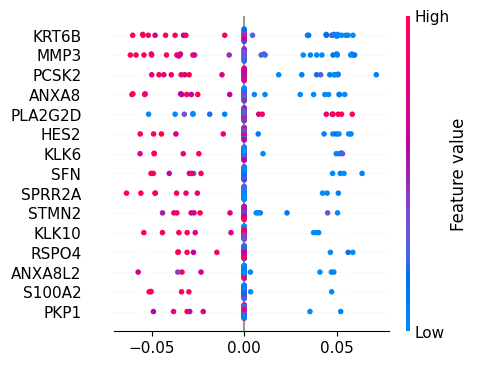

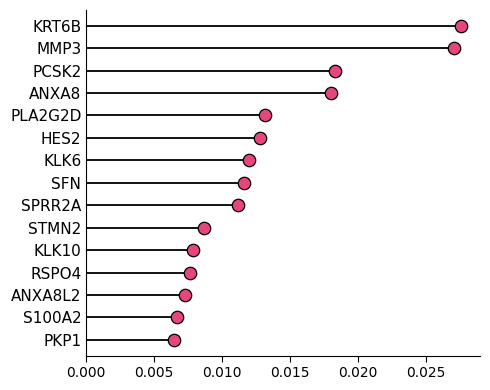


Running SHAP for model: Logistic Regression
Processing fold 1/5 for Logistic Regression...
Processing fold 2/5 for Logistic Regression...
Processing fold 3/5 for Logistic Regression...
Processing fold 4/5 for Logistic Regression...
Processing fold 5/5 for Logistic Regression...

Top 15 features sorted by mean |SHAP| for Logistic Regression:

['PLA2G2D', 'MMP3', 'PCSK2', 'GPRIN3', 'RSPO4', 'SYT5', 'HES2', 'SH3RF2', 'KLK6', 'SEPP1', 'SFTPC', 'ELF3', 'LAX1', 'CCNO', 'KLK10']

Numbered ranking:
 1. PLA2G2D    mean|SHAP| = 1.019757
 2. MMP3    mean|SHAP| = 0.769903
 3. PCSK2    mean|SHAP| = 0.500801
 4. GPRIN3    mean|SHAP| = 0.491041
 5. RSPO4    mean|SHAP| = 0.490862
 6. SYT5    mean|SHAP| = 0.312008
 7. HES2    mean|SHAP| = 0.282183
 8. SH3RF2    mean|SHAP| = 0.251779
 9. KLK6    mean|SHAP| = 0.218915
10. SEPP1    mean|SHAP| = 0.199511
11. SFTPC    mean|SHAP| = 0.150470
12. ELF3    mean|SHAP| = 0.127935
13. LAX1    mean|SHAP| = 0.115771
14. CCNO    mean|SHAP| = 0.115319
15. KLK10    mea

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate mask

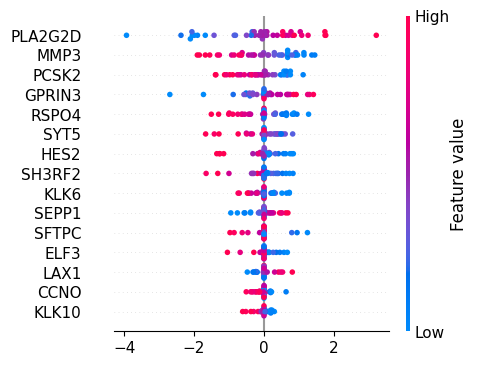

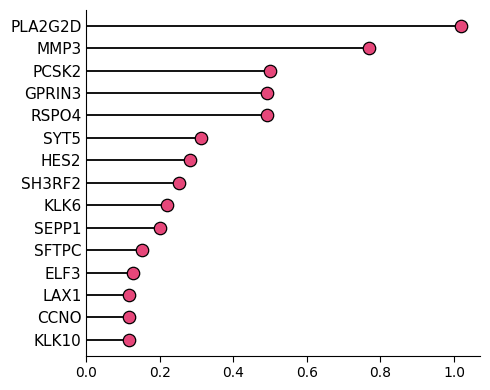


Running SHAP for model: Random Forest
Processing fold 1/5 for Random Forest...
Processing fold 2/5 for Random Forest...
Processing fold 3/5 for Random Forest...
Processing fold 4/5 for Random Forest...
Processing fold 5/5 for Random Forest...

Top 15 features sorted by mean |SHAP| for Random Forest:

['MMP3', 'ELF3', 'HES2', 'DNAJC5B', 'UBE2E3', 'SH3RF2', 'NARFL', 'WDR20', 'KRT10', 'ORAOV1', 'BRMS1', 'DCAF15', 'LOC100131726', 'RIPK4', 'PAK2']

Numbered ranking:
 1. MMP3    mean|SHAP| = 0.014206
 2. ELF3    mean|SHAP| = 0.008724
 3. HES2    mean|SHAP| = 0.008165
 4. DNAJC5B    mean|SHAP| = 0.008082
 5. UBE2E3    mean|SHAP| = 0.008064
 6. SH3RF2    mean|SHAP| = 0.007244
 7. NARFL    mean|SHAP| = 0.005747
 8. WDR20    mean|SHAP| = 0.005703
 9. KRT10    mean|SHAP| = 0.005627
10. ORAOV1    mean|SHAP| = 0.005516
11. BRMS1    mean|SHAP| = 0.005493
12. DCAF15    mean|SHAP| = 0.005456
13. LOC100131726    mean|SHAP| = 0.005341
14. RIPK4    mean|SHAP| = 0.005331
15. PAK2    mean|SHAP| = 0.005135

/tmp/ipykernel_2155/4210812763.py:160: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


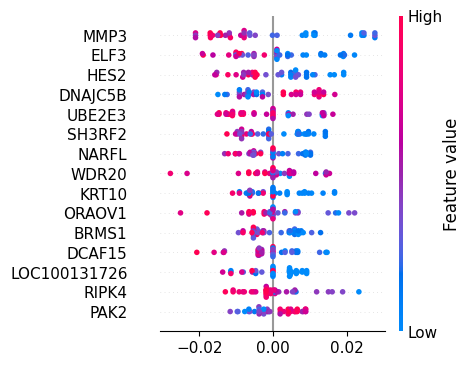

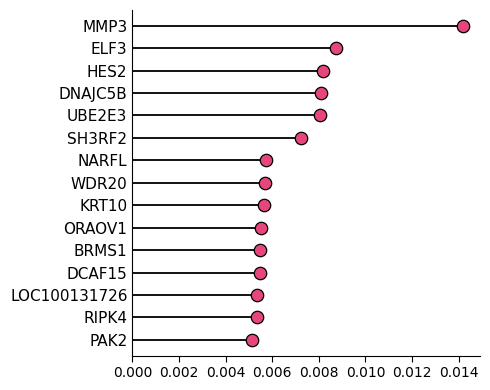


Number of unique SHAP genes from all three models: 34
Unique SHAP genes:
['KRT6B', 'MMP3', 'PCSK2', 'ANXA8', 'PLA2G2D', 'HES2', 'KLK6', 'SFN', 'SPRR2A', 'STMN2', 'KLK10', 'RSPO4', 'ANXA8L2', 'S100A2', 'PKP1', 'GPRIN3', 'SYT5', 'SH3RF2', 'SEPP1', 'SFTPC', 'ELF3', 'LAX1', 'CCNO', 'DNAJC5B', 'UBE2E3', 'NARFL', 'WDR20', 'KRT10', 'ORAOV1', 'BRMS1', 'DCAF15', 'LOC100131726', 'RIPK4', 'PAK2']

Saved dataset with unique SHAP genes and TumorType:
BEST_Subset_from_Step3.csv


In [ ]:
# ============================================================
# CONFIG
# ============================================================
INPUT_CSV = "BEST_Subset_from_Step2.csv"
TARGET_COL = "TumorType"
TOP_N = 15

N_SPLITS = 5
RANDOM_STATE_CV = 42
RANDOM_STATE_MODEL = 42


# ============================================================
# LOAD DATA
# ============================================================
data = pd.read_csv(INPUT_CSV)

X = data.drop(columns=[TARGET_COL])
y = data[TARGET_COL].values

feature_names = np.array(X.columns)


# ============================================================
# Update models. Consider top three performing models from step 2
# ============================================================

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(C=1, penalty='l1', solver='liblinear', max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_split=5, max_depth=None, random_state=42)
}



# ============================================================
# HELPER: normalize SHAP output
# ============================================================

def normalize_shap_values(shap_vals, n_features):
    """
    Convert SHAP output to shape:
    (n_samples, n_features)

    Handles:
    - list: [class0, class1]
    - 2D array: (n_samples, n_features)
    - 3D array: class dimension included
    """

    if isinstance(shap_vals, list):
        shap_arr = np.asarray(shap_vals[1]) if len(shap_vals) > 1 else np.asarray(shap_vals[0])
    else:
        shap_arr = np.asarray(shap_vals)

        # Case: (2, n_samples, n_features)
        if shap_arr.ndim == 3 and shap_arr.shape[0] == 2:
            shap_arr = shap_arr[1]

        # Case: (n_samples, n_features, 2)
        elif shap_arr.ndim == 3 and shap_arr.shape[-1] == 2:
            shap_arr = shap_arr[:, :, 1]

    if shap_arr.ndim != 2 or shap_arr.shape[1] != n_features:
        raise ValueError(
            f"Unexpected SHAP array shape {shap_arr.shape}; "
            f"expected (n_samples, n_features={n_features})"
        )

    return shap_arr


# ============================================================
# HELPER: get SHAP values for one model
# ============================================================

def get_shap_values_for_model(model_name, model, X_train, X_test):
    """
    Uses suitable SHAP explainer for each of the 11 models:
    - Logistic Regression, SVC linear: LinearExplainer, fallback KernelExplainer
    - Decision Tree, Extra Trees, Random Forest, Gradient Boost, XGBoost: TreeExplainer
    - AdaBoost, KNN, Naive Bayes, MLP: KernelExplainer
    """

    # The name can be written with or without spaces, e.g. "Extra Trees" or "ExtraTrees"
    key = model_name.replace(" ", "").lower()

    linear_models = ["logisticregression", "svc"]
    tree_models = ["decisiontree", "extratrees", "randomforest", "gradientboost", "xgboost"]
    kernel_models = ["adaboost", "knn", "naivebayes", "mlp"]

    def kernel_shap_values():
        background = shap.sample(
            X_train,
            min(100, X_train.shape[0]),
            random_state=RANDOM_STATE_MODEL
        )

        explainer = shap.KernelExplainer(
            model.predict_proba,
            background
        )

        # KernelExplainer samples at random; the seed gives the same result on every run
        np.random.seed(RANDOM_STATE_MODEL)

        return explainer.shap_values(
            X_test,
            nsamples="auto"
        )

    if key in linear_models:

        try:
            explainer = shap.LinearExplainer(
                model,
                X_train,
                feature_perturbation="interventional"
            )

            shap_vals = explainer.shap_values(X_test)

        except Exception:
            shap_vals = kernel_shap_values()


    elif key in tree_models:

        explainer = shap.TreeExplainer(model)
        shap_vals = explainer.shap_values(X_test)


    elif key in kernel_models:

        shap_vals = kernel_shap_values()

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return normalize_shap_values(
        shap_vals,
        n_features=X_train.shape[1]
    )


# ============================================================
# HELPER: make plots
# ============================================================

def make_shap_plots(model_name, shap_sorted, X_sorted, features_sorted, mean_abs_sorted):
    """
    Saves:
    - beeswarm plot as PNG
    - importance dot plot as PNG
    """

    # --------------------
    # Beeswarm plot
    # --------------------
    shap.summary_plot(
        shap_sorted,
        X_sorted,
        feature_names=list(features_sorted),
        max_display=len(features_sorted),
        show=False,
        plot_size=(5, 4)
    )

    ax = plt.gca()
    ax.tick_params(axis="both", colors="black")

    for spine in ax.spines.values():
        spine.set_edgecolor("black")

    plt.tight_layout()
    plt.yticks(fontsize=11)
    plt.xlabel("")

    plt.savefig(
        f"{model_name}_beeswarm_overall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # --------------------
    # Variable importance dot plot
    # --------------------
    plt.figure(figsize=(5, 4))

    y_pos = np.arange(len(features_sorted))

    for yi, xi in zip(y_pos, mean_abs_sorted):
        plt.hlines(
            yi,
            xmin=0,
            xmax=xi,
            color="black",
            linewidth=1.3,
            zorder=1.5
        )

    plt.scatter(
        mean_abs_sorted,
        y_pos,
        s=80,
        marker="o",
        facecolors="#E6477A",
        edgecolors="black",
        linewidths=0.9,
        zorder=3
    )

    ax = plt.gca()

    ax.tick_params(axis="y", which="both", length=0)
    ax.tick_params(axis="x", which="both", length=4)

    plt.yticks(y_pos, features_sorted, fontsize=11)
    plt.gca().invert_yaxis()
    plt.xlim(left=0)
    plt.grid(False)

    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

    plt.tight_layout()

    plt.savefig(
        f"{model_name}_importance_overall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()




skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE_CV
)

all_model_rankings = []

for model_name, base_model in models.items():

    print("\n" + "=" * 70)
    print(f"Running SHAP for model: {model_name}")
    print("=" * 70)

    shap_values_list = []
    X_rows_list = []
    y_rows_list = []

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):

        print(f"Processing fold {fold}/{N_SPLITS} for {model_name}...")

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        model = clone(base_model)
        model.fit(X_train, y_train)

        shap_arr = get_shap_values_for_model(
            model_name=model_name,
            model=model,
            X_train=X_train,
            X_test=X_test
        )

        shap_values_list.append(shap_arr)
        X_rows_list.append(X_test)
        y_rows_list.append(y_test)


    # ========================================================
    # Concatenate out-of-fold SHAP values
    # ========================================================

    all_shap_values = np.vstack(shap_values_list)
    all_X = pd.concat(X_rows_list, axis=0)
    all_y = np.concatenate(y_rows_list)


    # ========================================================
    # Rank features by mean absolute SHAP
    # ========================================================

    mean_abs_shap = np.abs(all_shap_values).mean(axis=0)

    top_indices = np.argsort(mean_abs_shap)[::-1][:TOP_N]

    features_top = feature_names[top_indices]
    mean_abs_top = mean_abs_shap[top_indices]

    order = np.argsort(mean_abs_top)[::-1]

    features_sorted = features_top[order]
    mean_abs_sorted = mean_abs_top[order]

    shap_sorted = all_shap_values[:, top_indices][:, order]
    X_sorted = all_X.iloc[:, top_indices].iloc[:, order]


    # ========================================================
    # Print ranking
    # ========================================================

    print(f"\nTop {TOP_N} features sorted by mean |SHAP| for {model_name}:\n")
    print(list(features_sorted))

    print("\nNumbered ranking:")

    for i, (feat, val) in enumerate(
        zip(features_sorted, mean_abs_sorted),
        start=1
    ):
        print(f"{i:2d}. {feat}    mean|SHAP| = {val:.6f}")

        all_model_rankings.append({
            "Model": model_name,
            "Rank": i,
            "Feature": feat,
            "MeanAbsSHAP": val
        })


    # ========================================================
    # Save plots
    # ========================================================

    make_shap_plots(
        model_name=model_name,
        shap_sorted=shap_sorted,
        X_sorted=X_sorted,
        features_sorted=features_sorted,
        mean_abs_sorted=mean_abs_sorted
    )


# ============================================================
# SAVE COMBINED SHAP RANKING TABLE
# ============================================================
ranking_df = pd.DataFrame(all_model_rankings)

# Get unique genes selected by SHAP across top three models
unique_shap_genes = ranking_df["Feature"].dropna().unique().tolist()

# Keep only genes that actually exist in the original dataset
unique_shap_genes = [gene for gene in unique_shap_genes if gene in data.columns]

print("\nNumber of unique SHAP genes from all three models:", len(unique_shap_genes))
print("Unique SHAP genes:")
print(unique_shap_genes)

# Create new dataframe with only unique SHAP genes and TumorType
unique_shap_dataset = data[unique_shap_genes].copy()
unique_shap_dataset[TARGET_COL] = data[TARGET_COL].values

# Save new dataset
unique_shap_dataset.to_csv(
    "BEST_Subset_from_Step3.csv",
    index=False
)

print("\nSaved dataset with unique SHAP genes and TumorType:")
print("BEST_Subset_from_Step3.csv")

**Step-4: Prognostic Verification and Clinical
Translation**

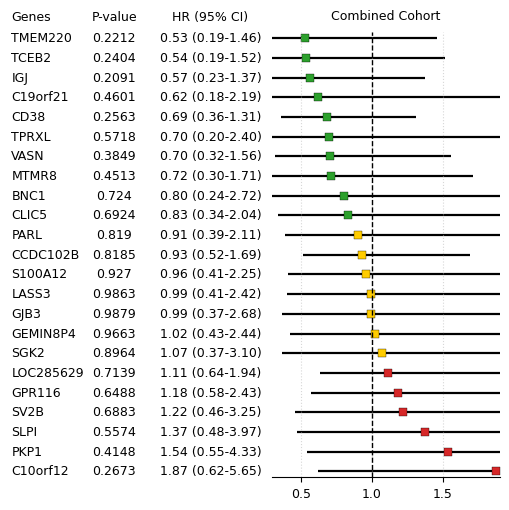

In [ ]:
# Update your genes list
csv_file = "Sample_BEST_Subset_from_Step3_with_Survival_Data.csv"
# Just Random Gene Names
genes = [
    'IGJ', 'PKP1', 'TPRXL', 'BNC1', 'MTMR8', 'SV2B', 'LASS3', 'CD38', 'C10orf12', 'GPR116', 'S100A12', 'VASN', 'SLPI', 'GJB3', 'GEMIN8P4', 'PARL', 'SGK2', 'CCDC102B', 'TCEB2', 'LOC285629', 'TMEM220', 'CLIC5', 'C19orf21'
]

# Layout: genes | p-value | HR text | forest
width_ratios = [0.085, 0.085, 0.15, 0.28]
font_size = 9
spacing_scale = 0.65

# Forest look
xleft, xright = (0.3, 1.9)
marker_size = 6
line_width = 1.6
hlines_color = "black"
vline_color = "black"

# ---------------- HELPERS ----------------
def fmt_p(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return "NA"
    p = float(p)
    if p == 0:
        return "0"
    if p < 1e-4:
        return f"{p:.1e}"
    s = f"{p:.4f}"
    return s.rstrip("0").rstrip(".")

def fmt_hr(hr, lo, hi):
    if any(pd.isna([hr, lo, hi])):
        return "NA"
    return f"{hr:.2f} ({lo:.2f}-{hi:.2f})"

def hr_color(hr, low=0.90, high=1.10):
    if hr is None or (isinstance(hr, float) and np.isnan(hr)):
        return "#B0B0B0"
    if hr < low:
        return "#2ca02c"
    if hr <= high:
        return "#ffcc00"
    return "#d62728"

# ---------------- LOAD DATA ----------------
cols = genes + ["TumorType", "OS", "OS.time"]
df = pd.read_csv(csv_file, usecols=lambda c: c in cols).dropna(subset=["OS", "OS.time", "TumorType"])
df["OS"] = df["OS"].astype(int)
df["OS.time"] = df["OS.time"].astype(float)

# ---------------- COX PER GENE (COMBINED ONLY) ----------------
out = []
for g in genes:
    d = df.dropna(subset=[g]).copy()
    n = len(d)
    events = int(d["OS"].sum())
    x = d[g].astype(float)
    iqr = float(x.quantile(0.75) - x.quantile(0.25))

    p = hr = lo = hi = np.nan
    if n > 0 and events > 0 and x.nunique() > 1 and np.isfinite(iqr) and iqr > 0:
        try:
            cox = d[["OS.time", "OS", "TumorType"]].copy()
            cox["x"] = x.values
            cph = CoxPHFitter()
            cph.fit(cox, duration_col="OS.time", event_col="OS", strata=["TumorType"])

            beta = float(cph.summary.loc["x", "coef"])
            se = float(cph.summary.loc["x", "se(coef)"])
            p = float(cph.summary.loc["x", "p"])

            # HR
            hr = math.exp(beta * iqr)
            lo = math.exp((beta - 1.96 * se) * iqr)
            hi = math.exp((beta + 1.96 * se) * iqr)
        except Exception:
            pass

    out.append({"gene": g, "p": p, "hr": hr, "lo": lo, "hi": hi})

res = pd.DataFrame(out).sort_values("hr", ascending=True, na_position="last").reset_index(drop=True)

# ---------------- PLOT ----------------
plt.rcParams.update({"font.size": font_size})
fig = plt.figure(figsize=(5, 5))
gs = gridspec.GridSpec(1, 4, width_ratios=width_ratios, wspace=0.005)

ax_gene = fig.add_subplot(gs[0])
ax_p = fig.add_subplot(gs[1])
ax_txt = fig.add_subplot(gs[2])
ax_forest = fig.add_subplot(gs[3])

y = (np.arange(len(res))[::-1]).astype(float) * spacing_scale

# Forest panel
ax_forest.set_xlim(xleft, xright)
ax_forest.set_yticks([])
ax_forest.grid(axis="x", linestyle=":", alpha=0.5)
ax_forest.axvline(1.0, color=vline_color, linestyle="--", linewidth=1)
for sp in ("left", "right", "top"):
    ax_forest.spines[sp].set_visible(False)

for i, r in res.iterrows():
    yy = y[i]
    hr, lo, hi = r["hr"], r["lo"], r["hi"]
    if pd.notna(lo) and pd.notna(hi):
        ax_forest.hlines(yy, lo, hi, color=hlines_color, linewidth=line_width, zorder=1)
    if pd.notna(hr):
        ax_forest.plot(hr, yy, marker="s", linestyle="None",
                       markerfacecolor=hr_color(hr), markeredgecolor="black",
                       markeredgewidth=0.25, markersize=marker_size, zorder=1.5)
    else:
        ax_forest.plot((xleft + xright) / 2, yy, "x", color="#B0B0B0", alpha=0.45, zorder=1.5)

# Shared y-lims (so text aligns with forest)
ymin, ymax = float(y.min()), float(y.max())
pad = 0.3 * spacing_scale
for ax in (ax_gene, ax_p, ax_txt, ax_forest):
    ax.set_ylim(ymin - pad, ymax + pad)

ax_forest.set_title("Combined Cohort", y=1.01, fontsize = 9)

# Text columns
for ax in (ax_gene, ax_p, ax_txt):
    ax.set_xlim(0, 1)
    ax.axis("off")

ax_gene.text(0.02, 1.02, "Genes", transform=ax_gene.transAxes, ha="left", va="bottom")
ax_p.text(0.5, 1.02, "P-value", transform=ax_p.transAxes, ha="center", va="bottom")
ax_txt.text(0.5, 1.02, "HR (95% CI)", transform=ax_txt.transAxes, ha="center", va="bottom")

for i, r in res.iterrows():
    yy = y[i]
    ax_gene.text(0.02, yy, r["gene"], ha="left", va="center", transform=ax_gene.transData)
    ax_p.text(0.5, yy, fmt_p(r["p"]), ha="center", va="center", transform=ax_p.transData)
    ax_txt.text(0.5, yy, fmt_hr(r["hr"], r["lo"], r["hi"]),
                ha="center", va="center", transform=ax_txt.transData)

plt.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.03)
plt.savefig("forest_plot.png", bbox_inches='tight')
plt.show()

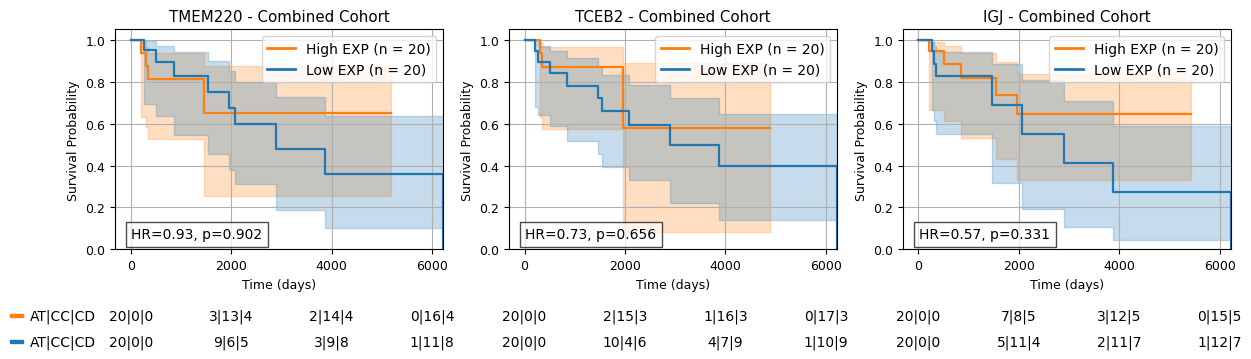

In [ ]:
genes = ['TMEM220', 'TCEB2', 'IGJ'] #Randomly picked, update the protective genes list
columns = genes + ['TumorType', 'OS', 'OS.time']

df = pd.read_csv("Sample_BEST_Subset_from_Step3_with_Survival_Data.csv", usecols=lambda c: c in columns)
df['OS'] = df['OS'].astype(int)
df['OS.time'] = df['OS.time'].astype(float)

# ONLY Combined cohort
tumor_types = ['Combined']

# Keep same per-panel size as the original 3x3 figure (14x14)
# Original panel size ~ (14/3, 14/3). Now 1 row x 3 panels => figsize=(14, 14/3)
fig, axes = plt.subplots(
    nrows=1, ncols=len(genes), figsize=(12, 12/3),
    gridspec_kw={'hspace': 0.6, 'wspace': 0.2}
)

# If axes is not an array (edge cases), normalize it
axes = np.array(axes).reshape(1, len(genes))

def get_cumulative_stats(times, events, xticks):
    n = len(times)
    cum_death, cum_censored, at_risk = [], [], []
    for tick in xticks:
        deaths = np.sum((events == 1) & (times < tick))
        censored = np.sum((events == 0) & (times < tick))
        still_at_risk = n - deaths - censored
        cum_death.append(deaths)
        cum_censored.append(censored)
        at_risk.append(still_at_risk)
    return at_risk, cum_censored, cum_death

at_risk_table = {}

for col, gene in enumerate(genes):
    ax = axes[0, col]

    subset = df.copy()  # Combined = all samples
    if subset.empty or gene not in subset:
        ax.axis('off')
        continue

    median_expr = subset[gene].median()
    subset['exp_group'] = np.where(subset[gene] > median_expr, 'High', 'Low')

    T = subset['OS.time'].to_numpy()
    E = subset['OS'].to_numpy()
    groups = subset['exp_group']

    colors = {'High': 'tab:orange', 'Low': 'tab:blue'}

    legend_handles, legend_labels = [], []
    for label in ['High', 'Low']:
        mask = (groups == label)
        n_samples = mask.sum()
        if n_samples == 0:
            continue
        legend_label = f"{label} EXP (n = {n_samples})"
        kmf = KaplanMeierFitter()
        kmf.fit(T[mask], event_observed=E[mask], label=legend_label)
        handle = kmf.plot_survival_function(ax=ax, color=colors[label], linewidth=1.6).get_lines()[-1]
        legend_handles.append(handle)
        legend_labels.append(legend_label)

    # Axis limits with padding
    min_time = 0
    max_time = subset['OS.time'].max()
    left_pad = 0.05
    upper_pad = 0.05
    x_range = max_time - min_time
    ax.set_xlim([min_time - left_pad * x_range, max_time])
    ax.set_ylim([0, 1 + upper_pad])

    # Combined ticks (same as your original "else" branch)
    xticks = [0, 2000, 4000, 6000]
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(x) for x in xticks])

    # AT / CC / CD stats for each group
    group_stats, cum_censored_stats, cum_death_stats = {}, {}, {}
    for label in ['High', 'Low']:
        mask = (groups == label)
        t_group = T[mask]
        e_group = E[mask]
        arisk, ccensored, cdeath = get_cumulative_stats(t_group, e_group, xticks)
        group_stats[label] = arisk
        cum_censored_stats[label] = ccensored
        cum_death_stats[label] = cdeath

    at_risk_table[(0, col)] = {
        'xticks': xticks,
        'high_atrisk': group_stats['High'],
        'low_atrisk': group_stats['Low'],
        'high_censored': cum_censored_stats['High'],
        'low_censored': cum_censored_stats['Low'],
        'high_death': cum_death_stats['High'],
        'low_death': cum_death_stats['Low'],
        'ax': ax
    }

    # Log-rank p-value
    mask_high = (groups == 'High')
    mask_low = (groups == 'Low')
    if mask_high.sum() > 0 and mask_low.sum() > 0:
        result = logrank_test(
            T[mask_high], T[mask_low],
            event_observed_A=E[mask_high],
            event_observed_B=E[mask_low]
        )
        p_value = result.p_value
    else:
        p_value = float('nan')

    # Cox HR (binary high vs low)
    cox_df = subset[[gene, 'OS.time', 'OS']].copy()
    cox_df['exp_group'] = (subset[gene] > median_expr).astype(int)
    cox_df['event'] = cox_df['OS']
    try:
        cph = CoxPHFitter()
        cph.fit(cox_df[['OS.time', 'event', 'exp_group']],
                duration_col='OS.time', event_col='event')
        hr = float(cph.hazard_ratios_['exp_group'])
    except Exception:
        hr = float('nan')

    annotation = f'HR={hr:.2f}, p={p_value:.3g}'
    ax.text(0.05, 0.05, annotation, transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.7))

    ax.set_title(f'{gene} - Combined Cohort')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Survival Probability')
    ax.grid(True)

    legend = ax.legend(handles=legend_handles, labels=legend_labels,
                       fontsize=10, loc="upper right", frameon=True)
    for legline in legend.get_lines():
        legline.set_linewidth(2)

# Adjust margins: keep enough bottom space for the AT|CC|CD table
plt.subplots_adjust(bottom=0.35, top=0.90, left=0.06, right=0.99)

# Positioning for at-risk table
y_high = -0.30
y_low = -0.42
bar_y_high = y_high
bar_y_low = y_low
label_x = -0.32
bar_width = 0.04
bar_height = 0.015

# Draw AT|CC|CD table under each plot
for col in range(len(genes)):
    d = at_risk_table.get((0, col), None)
    if d is None:
        continue
    ax = d['ax']
    xticks = d['xticks']

    high_atrisk = d['high_atrisk']
    low_atrisk = d['low_atrisk']
    high_censored = d['high_censored']
    low_censored = d['low_censored']
    high_death = d['high_death']
    low_death = d['low_death']

    xlim = ax.get_xlim()
    if xlim[1] - xlim[0] == 0:
        x_frac = [0] * len(xticks)
    else:
        x_frac = [(x - xlim[0]) / (xlim[1] - xlim[0]) for x in xticks]

    # Only for the leftmost plot, draw the colored bars and header text
    if col == 0:
        ax.add_patch(Rectangle((label_x, bar_y_high - bar_height / 2), bar_width, bar_height,
                               color="tab:orange", transform=ax.transAxes, clip_on=False))
        ax.text(label_x + bar_width + 0.02, bar_y_high, "AT|CC|CD", ha='left', va='center',
                color='black', fontsize=10, transform=ax.transAxes)

        ax.add_patch(Rectangle((label_x, bar_y_low - bar_height / 2), bar_width, bar_height,
                               color="tab:blue", transform=ax.transAxes, clip_on=False))
        ax.text(label_x + bar_width + 0.02, bar_y_low, "AT|CC|CD", ha='left', va='center',
                color='black', fontsize=10, transform=ax.transAxes)

    for i, frac in enumerate(x_frac):
        ax.text(frac, y_high, f"{high_atrisk[i]}|{high_censored[i]}|{high_death[i]}",
                ha='center', va='center', color='black', fontsize=10, transform=ax.transAxes)
        ax.text(frac, y_low, f"{low_atrisk[i]}|{low_censored[i]}|{low_death[i]}",
                ha='center', va='center', color='black', fontsize=10, transform=ax.transAxes)

plt.savefig("Protective Genes.png", bbox_inches="tight")
plt.show()

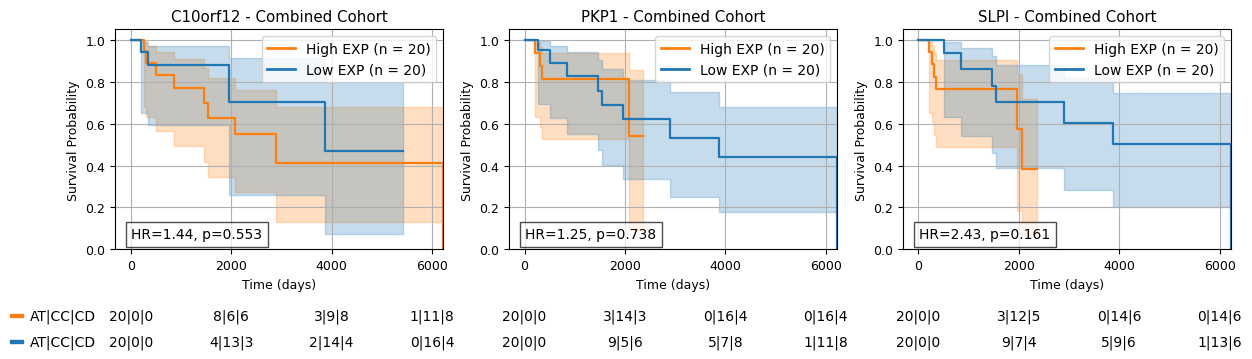

In [ ]:
genes = ['C10orf12', 'PKP1', 'SLPI'] #Randomly picked, update the risk genes list
columns = genes + ['TumorType', 'OS', 'OS.time']

df = pd.read_csv("Sample_BEST_Subset_from_Step3_with_Survival_Data.csv", usecols=lambda c: c in columns)
df['OS'] = df['OS'].astype(int)
df['OS.time'] = df['OS.time'].astype(float)

# ONLY Combined cohort
tumor_types = ['Combined']

# Keep same per-panel size as the original 3x3 figure (14x14)
# Original panel size ~ (14/3, 14/3). Now 1 row x 3 panels => figsize=(14, 14/3)
fig, axes = plt.subplots(
    nrows=1, ncols=len(genes), figsize=(12, 12/3),
    gridspec_kw={'hspace': 0.6, 'wspace': 0.2}
)

# If axes is not an array (edge cases), normalize it
axes = np.array(axes).reshape(1, len(genes))

def get_cumulative_stats(times, events, xticks):
    n = len(times)
    cum_death, cum_censored, at_risk = [], [], []
    for tick in xticks:
        deaths = np.sum((events == 1) & (times < tick))
        censored = np.sum((events == 0) & (times < tick))
        still_at_risk = n - deaths - censored
        cum_death.append(deaths)
        cum_censored.append(censored)
        at_risk.append(still_at_risk)
    return at_risk, cum_censored, cum_death

at_risk_table = {}

for col, gene in enumerate(genes):
    ax = axes[0, col]

    subset = df.copy()  # Combined = all samples
    if subset.empty or gene not in subset:
        ax.axis('off')
        continue

    median_expr = subset[gene].median()
    subset['exp_group'] = np.where(subset[gene] > median_expr, 'High', 'Low')

    T = subset['OS.time'].to_numpy()
    E = subset['OS'].to_numpy()
    groups = subset['exp_group']

    colors = {'High': 'tab:orange', 'Low': 'tab:blue'}

    legend_handles, legend_labels = [], []
    for label in ['High', 'Low']:
        mask = (groups == label)
        n_samples = mask.sum()
        if n_samples == 0:
            continue
        legend_label = f"{label} EXP (n = {n_samples})"
        kmf = KaplanMeierFitter()
        kmf.fit(T[mask], event_observed=E[mask], label=legend_label)
        handle = kmf.plot_survival_function(ax=ax, color=colors[label], linewidth=1.6).get_lines()[-1]
        legend_handles.append(handle)
        legend_labels.append(legend_label)

    # Axis limits with padding
    min_time = 0
    max_time = subset['OS.time'].max()
    left_pad = 0.05
    upper_pad = 0.05
    x_range = max_time - min_time
    ax.set_xlim([min_time - left_pad * x_range, max_time])
    ax.set_ylim([0, 1 + upper_pad])

    # Combined ticks (same as your original "else" branch)
    xticks = [0, 2000, 4000, 6000]
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(x) for x in xticks])

    # AT / CC / CD stats for each group
    group_stats, cum_censored_stats, cum_death_stats = {}, {}, {}
    for label in ['High', 'Low']:
        mask = (groups == label)
        t_group = T[mask]
        e_group = E[mask]
        arisk, ccensored, cdeath = get_cumulative_stats(t_group, e_group, xticks)
        group_stats[label] = arisk
        cum_censored_stats[label] = ccensored
        cum_death_stats[label] = cdeath

    at_risk_table[(0, col)] = {
        'xticks': xticks,
        'high_atrisk': group_stats['High'],
        'low_atrisk': group_stats['Low'],
        'high_censored': cum_censored_stats['High'],
        'low_censored': cum_censored_stats['Low'],
        'high_death': cum_death_stats['High'],
        'low_death': cum_death_stats['Low'],
        'ax': ax
    }

    # Log-rank p-value
    mask_high = (groups == 'High')
    mask_low = (groups == 'Low')
    if mask_high.sum() > 0 and mask_low.sum() > 0:
        result = logrank_test(
            T[mask_high], T[mask_low],
            event_observed_A=E[mask_high],
            event_observed_B=E[mask_low]
        )
        p_value = result.p_value
    else:
        p_value = float('nan')

    # Cox HR (binary high vs low)
    cox_df = subset[[gene, 'OS.time', 'OS']].copy()
    cox_df['exp_group'] = (subset[gene] > median_expr).astype(int)
    cox_df['event'] = cox_df['OS']
    try:
        cph = CoxPHFitter()
        cph.fit(cox_df[['OS.time', 'event', 'exp_group']],
                duration_col='OS.time', event_col='event')
        hr = float(cph.hazard_ratios_['exp_group'])
    except Exception:
        hr = float('nan')

    annotation = f'HR={hr:.2f}, p={p_value:.3g}'
    ax.text(0.05, 0.05, annotation, transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.7))

    ax.set_title(f'{gene} - Combined Cohort')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Survival Probability')
    ax.grid(True)

    legend = ax.legend(handles=legend_handles, labels=legend_labels,
                       fontsize=10, loc="upper right", frameon=True)
    for legline in legend.get_lines():
        legline.set_linewidth(2)

# Adjust margins: keep enough bottom space for the AT|CC|CD table
plt.subplots_adjust(bottom=0.35, top=0.90, left=0.06, right=0.99)

# Positioning for at-risk table
y_high = -0.30
y_low = -0.42
bar_y_high = y_high
bar_y_low = y_low
label_x = -0.32
bar_width = 0.04
bar_height = 0.015

# Draw AT|CC|CD table under each plot
for col in range(len(genes)):
    d = at_risk_table.get((0, col), None)
    if d is None:
        continue
    ax = d['ax']
    xticks = d['xticks']

    high_atrisk = d['high_atrisk']
    low_atrisk = d['low_atrisk']
    high_censored = d['high_censored']
    low_censored = d['low_censored']
    high_death = d['high_death']
    low_death = d['low_death']

    xlim = ax.get_xlim()
    if xlim[1] - xlim[0] == 0:
        x_frac = [0] * len(xticks)
    else:
        x_frac = [(x - xlim[0]) / (xlim[1] - xlim[0]) for x in xticks]

    # Only for the leftmost plot, draw the colored bars and header text
    if col == 0:
        ax.add_patch(Rectangle((label_x, bar_y_high - bar_height / 2), bar_width, bar_height,
                               color="tab:orange", transform=ax.transAxes, clip_on=False))
        ax.text(label_x + bar_width + 0.02, bar_y_high, "AT|CC|CD", ha='left', va='center',
                color='black', fontsize=10, transform=ax.transAxes)

        ax.add_patch(Rectangle((label_x, bar_y_low - bar_height / 2), bar_width, bar_height,
                               color="tab:blue", transform=ax.transAxes, clip_on=False))
        ax.text(label_x + bar_width + 0.02, bar_y_low, "AT|CC|CD", ha='left', va='center',
                color='black', fontsize=10, transform=ax.transAxes)

    for i, frac in enumerate(x_frac):
        ax.text(frac, y_high, f"{high_atrisk[i]}|{high_censored[i]}|{high_death[i]}",
                ha='center', va='center', color='black', fontsize=10, transform=ax.transAxes)
        ax.text(frac, y_low, f"{low_atrisk[i]}|{low_censored[i]}|{low_death[i]}",
                ha='center', va='center', color='black', fontsize=10, transform=ax.transAxes)

plt.savefig("Risk Genes.png", bbox_inches="tight")
plt.show()